In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


In [3]:
df = pd.read_csv("Wine.csv")

print(df.head())
print(df.shape)
print(df.isnull().sum())

   Alcohol  Malic_Acid   Ash  Ash_Alcanity  Magnesium  Total_Phenols  \
0    14.23        1.71  2.43          15.6        127           2.80   
1    13.20        1.78  2.14          11.2        100           2.65   
2    13.16        2.36  2.67          18.6        101           2.80   
3    14.37        1.95  2.50          16.8        113           3.85   
4    13.24        2.59  2.87          21.0        118           2.80   

   Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  Color_Intensity   Hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   OD280  Proline  Customer_Segment  
0   3.92     1065                 1  
1   3.40     105

In [4]:
x = df.drop("Customer_Segment", axis=1)
y = df["Customer_Segment"]

In [5]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)


In [6]:
pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_scaled)


In [7]:
pca_df = pd.DataFrame(
    x_pca,
    columns=["PC1","PC2"]
)

In [9]:
pca_df["Customer_Segment"] = y.values
print("\n PCA Transformed Data:")
print(pca_df.head())


 PCA Transformed Data:
        PC1       PC2  Customer_Segment
0  3.316751  1.443463                 1
1  2.209465 -0.333393                 1
2  2.516740  1.031151                 1
3  3.757066  2.756372                 1
4  1.008908  0.869831                 1


In [10]:
print("\n Explained variance Ratio:")
print(pca.explained_variance_ratio_)

print("Total Variance:")
print(sum(pca.explained_variance_ratio_))


 Explained variance Ratio:
[0.36198848 0.1920749 ]
Total Variance:
0.5540633835693527


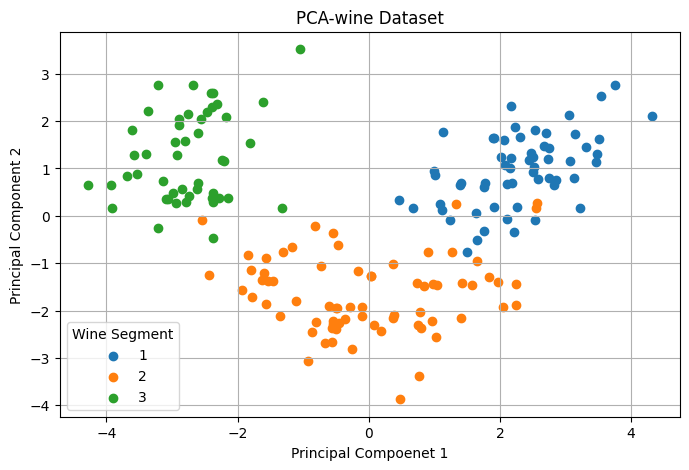

In [11]:
plt.figure(figsize=(8,5))

for segment in pca_df["Customer_Segment"].unique():
    data = pca_df[pca_df["Customer_Segment"] == segment]
    plt.scatter(data["PC1"],data["PC2"], label=segment)

plt.xlabel("Principal Compoenet 1")
plt.ylabel("Principal Component 2")
plt.title("PCA-wine Dataset")
plt.legend(title="Wine Segment")
plt.grid()
plt.show()